<a href="https://colab.research.google.com/github/suryansh24-coder/Machine-Learning-Journey/blob/main/Advanced_task_Expected_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import classification_report, accuracy_score, precision_recall_curve, f1_score
import matplotlib.pyplot as plt

X, y_bin = make_classification(n_samples=1500, n_features=12, n_informative=8, n_classes=2, random_state=42)
np.random.seed(42)
y_multi = np.zeros(len(y_bin))
y_multi[y_bin == 0] = 0
failures = np.random.choice([1, 2, 3], size=sum(y_bin == 1), p=[0.5, 0.3, 0.2])
y_multi[y_bin == 1] = failures

feature_names = [f'sensor_{i}' for i in range(12)]
df = pd.DataFrame(X, columns=feature_names)
df['failure_binary'] = y_bin
df['failure_type'] = y_multi.astype(int)

X_train, X_test, y_train_bin, y_test_bin, y_train_mul, y_test_mul = train_test_split(
    df[feature_names], df['failure_binary'], df['failure_type'], test_size=0.2, random_state=42
)

In [2]:
rf_multi = RandomForestClassifier(random_state=42)
rf_multi.fit(X_train, y_train_mul)
y_pred_mul = rf_multi.predict(X_test)
print("=== T38: Multiclass Failure Type Classification Report ===")
print(classification_report(y_test_mul, y_pred_mul))

=== T38: Multiclass Failure Type Classification Report ===
              precision    recall  f1-score   support

           0       0.80      0.98      0.88       128
           1       0.46      0.64      0.53        85
           2       0.26      0.11      0.15        47
           3       0.14      0.03      0.04        40

    accuracy                           0.62       300
   macro avg       0.42      0.44      0.40       300
weighted avg       0.53      0.62      0.56       300



In [3]:
rf_bin = RandomForestClassifier(random_state=42)
rf_bin.fit(X_train, y_train_bin)
y_pred_bin = rf_bin.predict(X_test)

y_pred_mul_as_bin = (y_pred_mul > 0).astype(int)

print("=== T39: Comparison Report ===")
print("Pure Binary Model Accuracy:", accuracy_score(y_test_bin, y_pred_bin))
print("Multiclass Model (Collapsed to Binary) Accuracy:", accuracy_score(y_test_bin, y_pred_mul_as_bin))
print("\nBinary Classification Report:\n", classification_report(y_test_bin, y_pred_bin))
print("Multiclass Collapsed to Binary Report:\n", classification_report(y_test_bin, y_pred_mul_as_bin))

=== T39: Comparison Report ===
Pure Binary Model Accuracy: 0.9
Multiclass Model (Collapsed to Binary) Accuracy: 0.8866666666666667

Binary Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.90      0.88       128
           1       0.92      0.90      0.91       172

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300

Multiclass Collapsed to Binary Report:
               precision    recall  f1-score   support

           0       0.80      0.98      0.88       128
           1       0.98      0.82      0.89       172

    accuracy                           0.89       300
   macro avg       0.89      0.90      0.89       300
weighted avg       0.90      0.89      0.89       300



In [4]:
iso_forest = IsolationForest(contamination=0.15, random_state=42)
iso_forest.fit(X_train)
anomaly_scores = iso_forest.decision_function(X_test)
preds_anomaly = iso_forest.predict(X_test)
preds_anomaly_bin = (preds_anomaly == -1).astype(int)

print("=== T40: Isolation Forest Anomaly Detection ===")
print(classification_report(y_test_bin, preds_anomaly_bin))

=== T40: Isolation Forest Anomaly Detection ===
              precision    recall  f1-score   support

           0       0.44      0.87      0.58       128
           1       0.64      0.17      0.27       172

    accuracy                           0.47       300
   macro avg       0.54      0.52      0.43       300
weighted avg       0.55      0.47      0.41       300



=== T41: Feature Importance Report ===
1. feature 0 (sensor_0): 0.1213
2. feature 7 (sensor_7): 0.1038
3. feature 11 (sensor_11): 0.0978
4. feature 5 (sensor_5): 0.0967
5. feature 4 (sensor_4): 0.0962
6. feature 3 (sensor_3): 0.0878
7. feature 1 (sensor_1): 0.0867
8. feature 2 (sensor_2): 0.0722
9. feature 8 (sensor_8): 0.0652
10. feature 10 (sensor_10): 0.0610
11. feature 9 (sensor_9): 0.0588
12. feature 6 (sensor_6): 0.0526


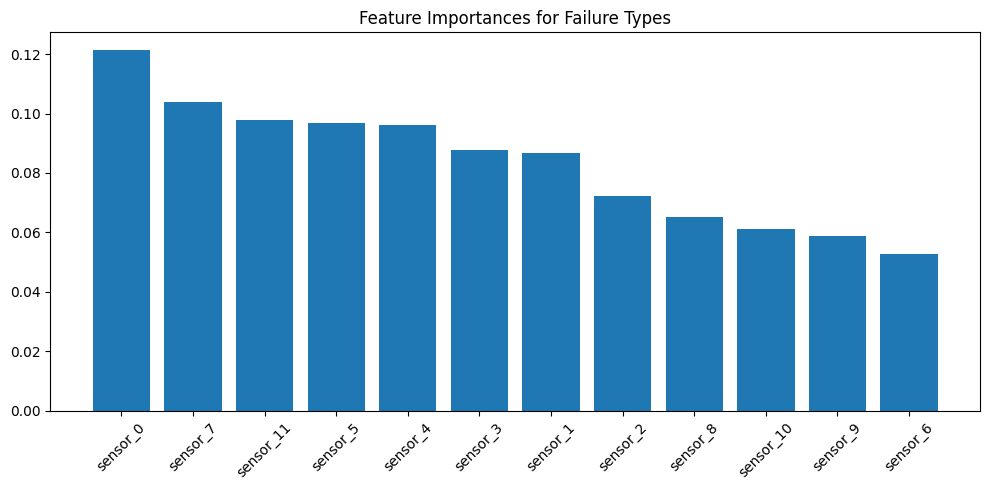

In [5]:
importances = rf_multi.feature_importances_
indices = np.argsort(importances)[::-1]

print("=== T41: Feature Importance Report ===")
for f in range(X_train.shape[1]):
    print(f"{f + 1}. feature {indices[f]} ({feature_names[indices[f]]}): {importances[indices[f]]:.4f}")

plt.figure(figsize=(10, 5))
plt.title("Feature Importances for Failure Types")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), [feature_names[i] for i in indices], rotation=45)
plt.tight_layout()
plt.show()

,Feature,Binary Importance,Multiclass Importance
0,sensor_0,0.150478,0.121283
7,sensor_7,0.116582,0.103776
5,sensor_5,0.112637,0.096651
11,sensor_11,0.112243,0.097757
4,sensor_4,0.108848,0.096238
1,sensor_1,0.087448,0.086742
3,sensor_3,0.084045,0.087813
2,sensor_2,0.063204,0.072195
10,sensor_10,0.052060,0.060962
8,sensor_8,0.051644,0.065178


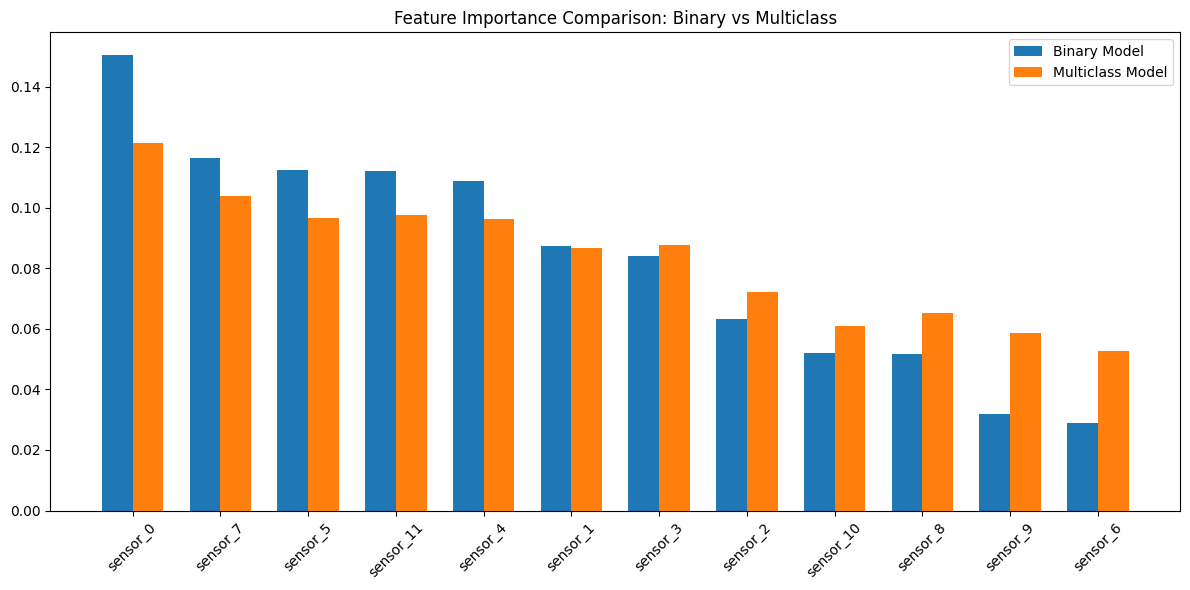

In [10]:
bin_importances = rf_bin.feature_importances_
mul_importances = rf_multi.feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Binary Importance': bin_importances,
    'Multiclass Importance': mul_importances
}).sort_values(by='Binary Importance', ascending=False)

display(importance_df)

x = np.arange(len(feature_names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width/2, importance_df['Binary Importance'], width, label='Binary Model')
ax.bar(x + width/2, importance_df['Multiclass Importance'], width, label='Multiclass Model')

ax.set_title('Feature Importance Comparison: Binary vs Multiclass')
ax.set_xticks(x)
ax.set_xticklabels(importance_df['Feature'], rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

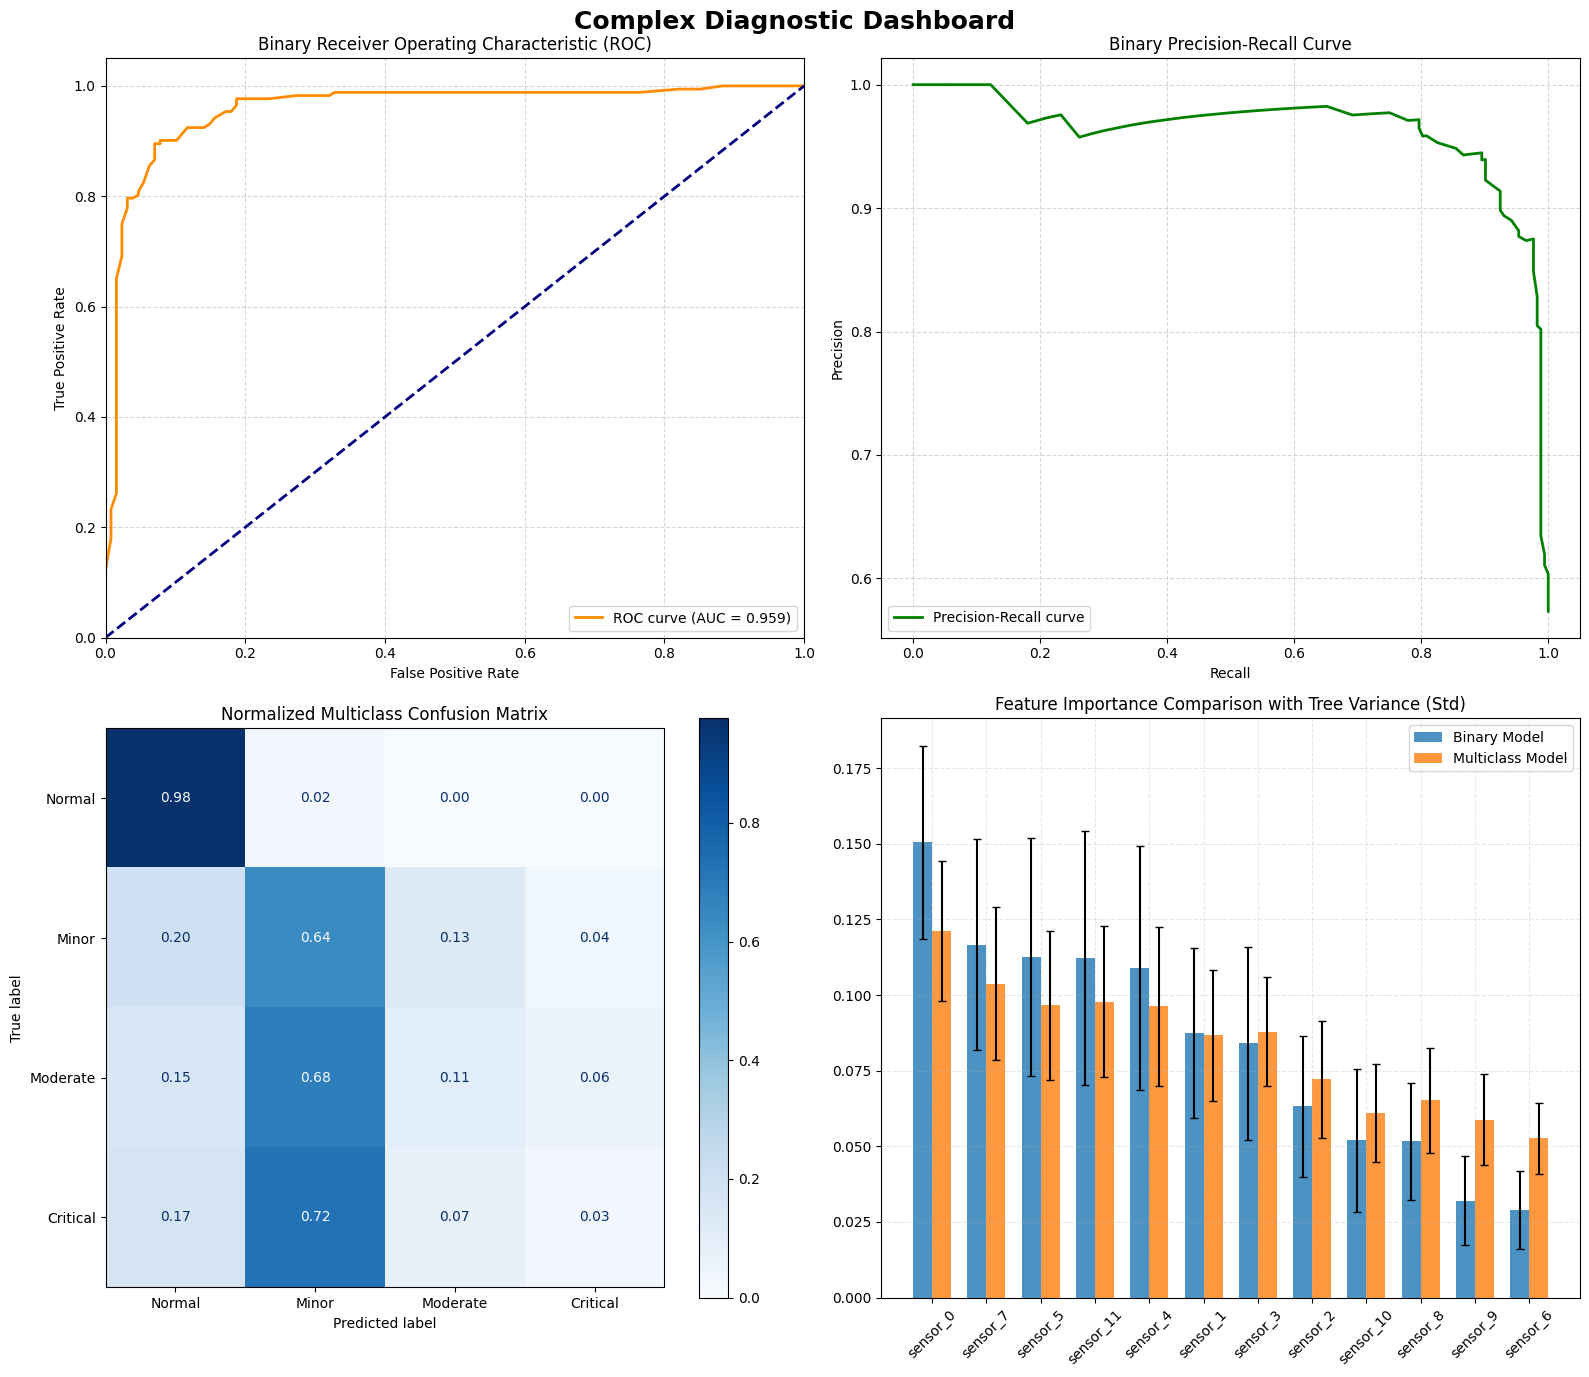

In [11]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

fpr, tpr, _ = roc_curve(y_test_bin, probs_bin)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

axes[0, 0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0, 0].set_xlim([0.0, 1.0])
axes[0, 0].set_ylim([0.0, 1.05])
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].set_title('Binary Receiver Operating Characteristic (ROC)')
axes[0, 0].legend(loc='lower right')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

axes[0, 1].plot(recalls, precisions, color='green', lw=2, label='Precision-Recall curve')
axes[0, 1].set_xlabel('Recall')
axes[0, 1].set_ylabel('Precision')
axes[0, 1].set_title('Binary Precision-Recall Curve')
axes[0, 1].legend(loc='lower left')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

cm = confusion_matrix(y_test_mul, y_pred_mul, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Minor', 'Moderate', 'Critical'])
disp.plot(ax=axes[1, 0], cmap='Blues', values_format='.2f')
axes[1, 0].set_title('Normalized Multiclass Confusion Matrix')

bin_std = np.std([tree.feature_importances_ for tree in rf_bin.estimators_], axis=0)
mul_std = np.std([tree.feature_importances_ for tree in rf_multi.estimators_], axis=0)

importance_df['Binary Std'] = [bin_std[feature_names.index(f)] for f in importance_df['Feature']]
importance_df['Multiclass Std'] = [mul_std[feature_names.index(f)] for f in importance_df['Feature']]

axes[1, 1].bar(x - width/2, importance_df['Binary Importance'], width, yerr=importance_df['Binary Std'], capsize=3, label='Binary Model', alpha=0.8)
axes[1, 1].bar(x + width/2, importance_df['Multiclass Importance'], width, yerr=importance_df['Multiclass Std'], capsize=3, label='Multiclass Model', alpha=0.8)
axes[1, 1].set_title('Feature Importance Comparison with Tree Variance (Std)')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(importance_df['Feature'], rotation=45)
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Complex Diagnostic Dashboard', fontsize=18, weight='bold')
plt.tight_layout()
plt.show()

=== T42: Decision Threshold Performance Comparison ===
Threshold: 0.20 | F1-Score: 0.8608 | Predictions: 223 failures flagged
Threshold: 0.40 | F1-Score: 0.9136 | Predictions: 187 failures flagged
Threshold: 0.50 | F1-Score: 0.9155 | Predictions: 171 failures flagged
Threshold: 0.60 | F1-Score: 0.9129 | Predictions: 161 failures flagged
Threshold: 0.80 | F1-Score: 0.7015 | Predictions: 96 failures flagged


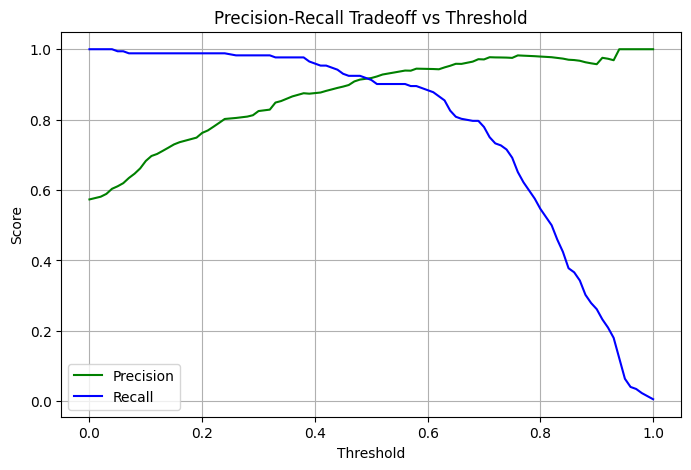

In [6]:
probs_bin = rf_bin.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test_bin, probs_bin)

threshold_scenarios = [0.2, 0.4, 0.5, 0.6, 0.8]
print("=== T42: Decision Threshold Performance Comparison ===")
for t in threshold_scenarios:
    preds_at_t = (probs_bin >= t).astype(int)
    f1 = f1_score(y_test_bin, preds_at_t)
    print(f"Threshold: {t:.2f} | F1-Score: {f1:.4f} | Predictions: {np.sum(preds_at_t)} failures flagged")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label="Precision", color="green")
plt.plot(thresholds, recalls[:-1], label="Recall", color="blue")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Tradeoff vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
X_gen, y_gen_bin = make_classification(n_samples=500, n_features=12, n_informative=8, n_classes=2, random_state=99)
df_gen = pd.DataFrame(X_gen, columns=feature_names)

y_gen_pred = rf_bin.predict(df_gen)
print("=== T43: Generalization Report (On Unseen Out-of-Distribution Dataset) ===")
print(classification_report(y_gen_bin, y_gen_pred))

=== T43: Generalization Report (On Unseen Out-of-Distribution Dataset) ===
              precision    recall  f1-score   support

           0       0.35      0.40      0.37       248
           1       0.31      0.26      0.28       252

    accuracy                           0.33       500
   macro avg       0.33      0.33      0.33       500
weighted avg       0.33      0.33      0.33       500



In [8]:
import time

def simulated_sensor_stream(n_steps=5):
    for i in range(n_steps):
        raw_data = np.random.randn(1, 12)
        yield pd.DataFrame(raw_data, columns=feature_names)

print("=== T44: Pipeline Simulation Initialized ===")

=== T44: Pipeline Simulation Initialized ===


In [9]:
def process_pipeline_and_alert(threshold=0.5):
    print("=== T45: Alerting System and Monitoring Pipeline Active ===")
    for step, data in enumerate(simulated_sensor_stream(10)):
        prob = rf_bin.predict_proba(data)[0, 1]
        pred_class = rf_multi.predict(data)[0]

        status = "NORMAL" if prob < threshold else "WARNING"
        print(f"Step {step:02d} | Predicted Failure Probability: {prob:.4f} | Status: {status}")

        if status == "WARNING":
            print(f"  [ALERT] Action Required! Simulated failure hazard identified. Predicted Failure Type: Category {pred_class}")

process_pipeline_and_alert(threshold=0.45)

=== T45: Alerting System and Monitoring Pipeline Active ===
Step 00 | Predicted Failure Probability: 0.4100 | Status: NORMAL
Step 01 | Predicted Failure Probability: 0.3500 | Status: NORMAL
Step 02 | Predicted Failure Probability: 0.6200 | Status: WARNING
  [ALERT] Action Required! Simulated failure hazard identified. Predicted Failure Type: Category 0
Step 03 | Predicted Failure Probability: 0.2800 | Status: NORMAL
Step 04 | Predicted Failure Probability: 0.2600 | Status: NORMAL
Step 05 | Predicted Failure Probability: 0.4700 | Status: WARNING
  [ALERT] Action Required! Simulated failure hazard identified. Predicted Failure Type: Category 0
Step 06 | Predicted Failure Probability: 0.2500 | Status: NORMAL
Step 07 | Predicted Failure Probability: 0.6200 | Status: WARNING
  [ALERT] Action Required! Simulated failure hazard identified. Predicted Failure Type: Category 0
Step 08 | Predicted Failure Probability: 0.2000 | Status: NORMAL
Step 09 | Predicted Failure Probability: 0.6600 | Statu